# BÁO CÁO PHÂN TÍCH KẾT QUẢ THỰC NGHIỆM CHUYÊN SÂU (RESULTS ANALYSIS) — LAB 2
**Chủ đề:** Deep Learning — Phân tích Định lượng Kết quả Thực nghiệm trên CIFAR-10  
**Tài liệu tham chiếu:** Chương 3 — Training Deep Neural Networks  

---

### Mục tiêu phân tích
Notebook này được thiết kế chuyên biệt để phân tích định lượng toàn diện kết quả thực nghiệm từ các tệp `outputs/metrics/*.json` và `outputs/metrics/summary.csv`:
1. **Chỉ đọc dữ liệu, không huấn luyện lại:** Không tải dataset CIFAR-10, không cập nhật trọng số mạng, đảm bảo tính bất biến của kết quả thực nghiệm.
2. **Tổng hợp đa chiều:** So sánh đối chứng giữa 4 thí nghiệm cốt lõi (ResNet18 vs. DenseNet121, Transfer Learning vs. Fine-Tuning) và 2 thí nghiệm điều chỉnh siêu tham số (Learning Rate $10^{-4}$, Batch Size $32$).
3. **Trực quan hóa đường cong học tập:** Vẽ đường cong Train/Val Loss và Train/Val Accuracy theo từng epoch để xác định tốc độ hội tụ và phân tích hiện tượng Overfitting/Underfitting.
4. **Phân tích ma trận nhầm lẫn:** Khảo sát độ chính xác theo từng lớp (Per-class Accuracy) và tự động trích xuất các cặp lớp hay nhầm lẫn nhất (Top Confused Pairs).
5. **Tính trung thực khoa học:** Mọi phân tích định lượng đều bám sát vào con số thực tế, có chú thích rõ ràng về giới hạn của việc thực nghiệm trên một seed ngẫu nhiên duy nhất (`seed=42`).

---

### Mục lục
1. [Thiết lập môi trường và nạp kết quả](#1-thiết-lập-môi-trường-và-nạp-kết-quả)
2. [Bảng tổng hợp kết quả các thí nghiệm](#2-bảng-tổng-hợp-kết-quả-các-thí-nghiệm)
3. [Đường cong học tập Loss và Accuracy theo Epoch](#3-đường-cong-học-tập-loss-và-accuracy-theo-epoch)
4. [So sánh Test Accuracy, Thời gian huấn luyện và Tham số Trainable](#4-so-sánh-test-accuracy-thời-gian-huấn-luyện-và-tham-số-trainable)
5. [Độ chính xác theo từng lớp và Phân tích Cặp lớp nhầm nhiều nhất](#5-độ-chính-xác-theo-từng-lớp-và-phân-tích-cặp-lớp-nhầm-nhiều-nhất)
6. [Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix Figures)](#6-trực-quan-hóa-ma-trận-nhầm-lẫn-confusion-matrix-figures)
7. [Phân tích hiện tượng Quá khớp (Overfitting) và Dưới khớp (Underfitting)](#7-phân-tích-hiện-tượng-quá-khớp-overfitting-và-dưới-khớp-underfitting)
8. [Tổng kết và Kiến nghị](#8-tổng-kết-và-kiến-nghị)

In [1]:
# Thiết lập đường dẫn thư mục gốc dự án độc lập với môi trường chạy
import os
import sys

current_path = os.path.abspath("")
while current_path != os.path.dirname(current_path):
    if os.path.exists(os.path.join(current_path, "src")) and os.path.exists(os.path.join(current_path, "configs")):
        break
    current_path = os.path.dirname(current_path)

PROJECT_ROOT = current_path
if os.path.join(PROJECT_ROOT, "src") not in sys.path:
    sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))

os.chdir(PROJECT_ROOT)
print(f"Project root xác định: {os.path.abspath('.')}")

Project root xác định: d:\Hoc_Sau\Lab 2


In [2]:
import glob
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

summary_csv = "./outputs/metrics/summary.csv"
history_files = sorted(glob.glob("./outputs/metrics/*_history.json"))
test_files = sorted(glob.glob("./outputs/metrics/*_test_metrics.json"))

print(f"File summary.csv khả dụng: {os.path.exists(summary_csv)}")
print(f"Số lượng file history JSON tìm thấy: {len(history_files)}")
print(f"Số lượng file test metrics JSON tìm thấy: {len(test_files)}")

# Nạp toàn bộ history vào dictionary
histories = {}
for hf in history_files:
    exp_name = os.path.basename(hf).replace("_history.json", "")
    with open(hf, "r", encoding="utf-8") as f:
        histories[exp_name] = json.load(f)

# Nạp toàn bộ test metrics vào dictionary
test_metrics = {}
for tf in test_files:
    exp_name = os.path.basename(tf).replace("_test_metrics.json", "")
    with open(tf, "r", encoding="utf-8") as f:
        test_metrics[exp_name] = json.load(f)

print(f"Các thí nghiệm có dữ liệu history: {list(histories.keys())}")
print(f"Các thí nghiệm có dữ liệu test metrics: {list(test_metrics.keys())}")

File summary.csv khả dụng: True
Số lượng file history JSON tìm thấy: 6
Số lượng file test metrics JSON tìm thấy: 6
Các thí nghiệm có dữ liệu history: ['densenet121_finetune', 'densenet121_transfer', 'resnet18_finetune', 'resnet18_transfer_bs32', 'resnet18_transfer', 'resnet18_transfer_lr1e4']
Các thí nghiệm có dữ liệu test metrics: ['densenet121_finetune', 'densenet121_transfer', 'resnet18_finetune', 'resnet18_transfer_bs32', 'resnet18_transfer_lr1e4', 'resnet18_transfer']


## 2. Bảng Tổng hợp Kết quả Các Thí nghiệm
Bảng số liệu tổng hợp các thí nghiệm (bao gồm 4 thí nghiệm cốt lõi và 2 thí nghiệm điều chỉnh siêu tham số) được sinh tự động bởi `scripts/make_results_table.py`.

In [3]:
if os.path.exists(summary_csv):
    df_summary = pd.read_csv(summary_csv)
    print("=== BẢNG TỔNG HỢP KẾT QUẢ THỰC NGHIỆM (outputs/metrics/summary.csv) ===")
    display(df_summary)
else:
    print("Chưa có file summary.csv. Khi chạy xong Phase 5 (huấn luyện đầy đủ), bảng số liệu tổng hợp sẽ xuất hiện tại đây.")

=== BẢNG TỔNG HỢP KẾT QUẢ THỰC NGHIỆM (outputs/metrics/summary.csv) ===


,Experiment ID,Epochs,Batch,LR,Trainable params,Train Loss/Acc (epoch cuối),Best Val Acc (epoch),Test Loss,Test Acc,Thời gian TB mỗi epoch,Tổng thời gian
0,resnet18_transfer,5,16,0.0010,"5,130",0.7718 / 73.85%,77.94% (ep 2),0.6644,77.98%,01m 06s,05m 35s
1,resnet18_finetune,5,16,0.0010,"8,398,858",0.2488 / 91.48%,91.68% (ep 4),0.2989,90.24%,01m 26s,07m 15s
2,densenet121_transfer,5,16,0.0010,"10,250",0.6860 / 76.89%,81.84% (ep 5),0.5560,81.34%,01m 48s,09m 03s
3,densenet121_finetune,5,16,0.0010,"2,170,378",0.2912 / 89.94%,90.78% (ep 5),0.2982,90.65%,02m 08s,10m 42s
4,resnet18_transfer_lr1e4,5,16,0.0001,"5,130",0.7605 / 73.96%,77.56% (ep 5),0.6643,78.32%,01m 12s,06m 03s
5,resnet18_transfer_bs32,5,32,0.0010,"5,130",0.7029 / 76.12%,78.92% (ep 4),0.6276,79.04%,01m 04s,05m 21s


## 3. Đường cong Học tập Loss và Accuracy theo Epoch
Biểu đồ theo dõi sự thay đổi của hàm mất mát (`Loss/train`, `Loss/val`) và độ chính xác (`Accuracy/train`, `Accuracy/val`) qua từng epoch từ các file `*_history.json`:
- Đánh giá tốc độ hội tụ (convergence speed) của các kiến trúc.
- Quan sát độ lệch (gap) giữa train và validation để nhận diện sớm hiện tượng quá khớp (Overfitting).

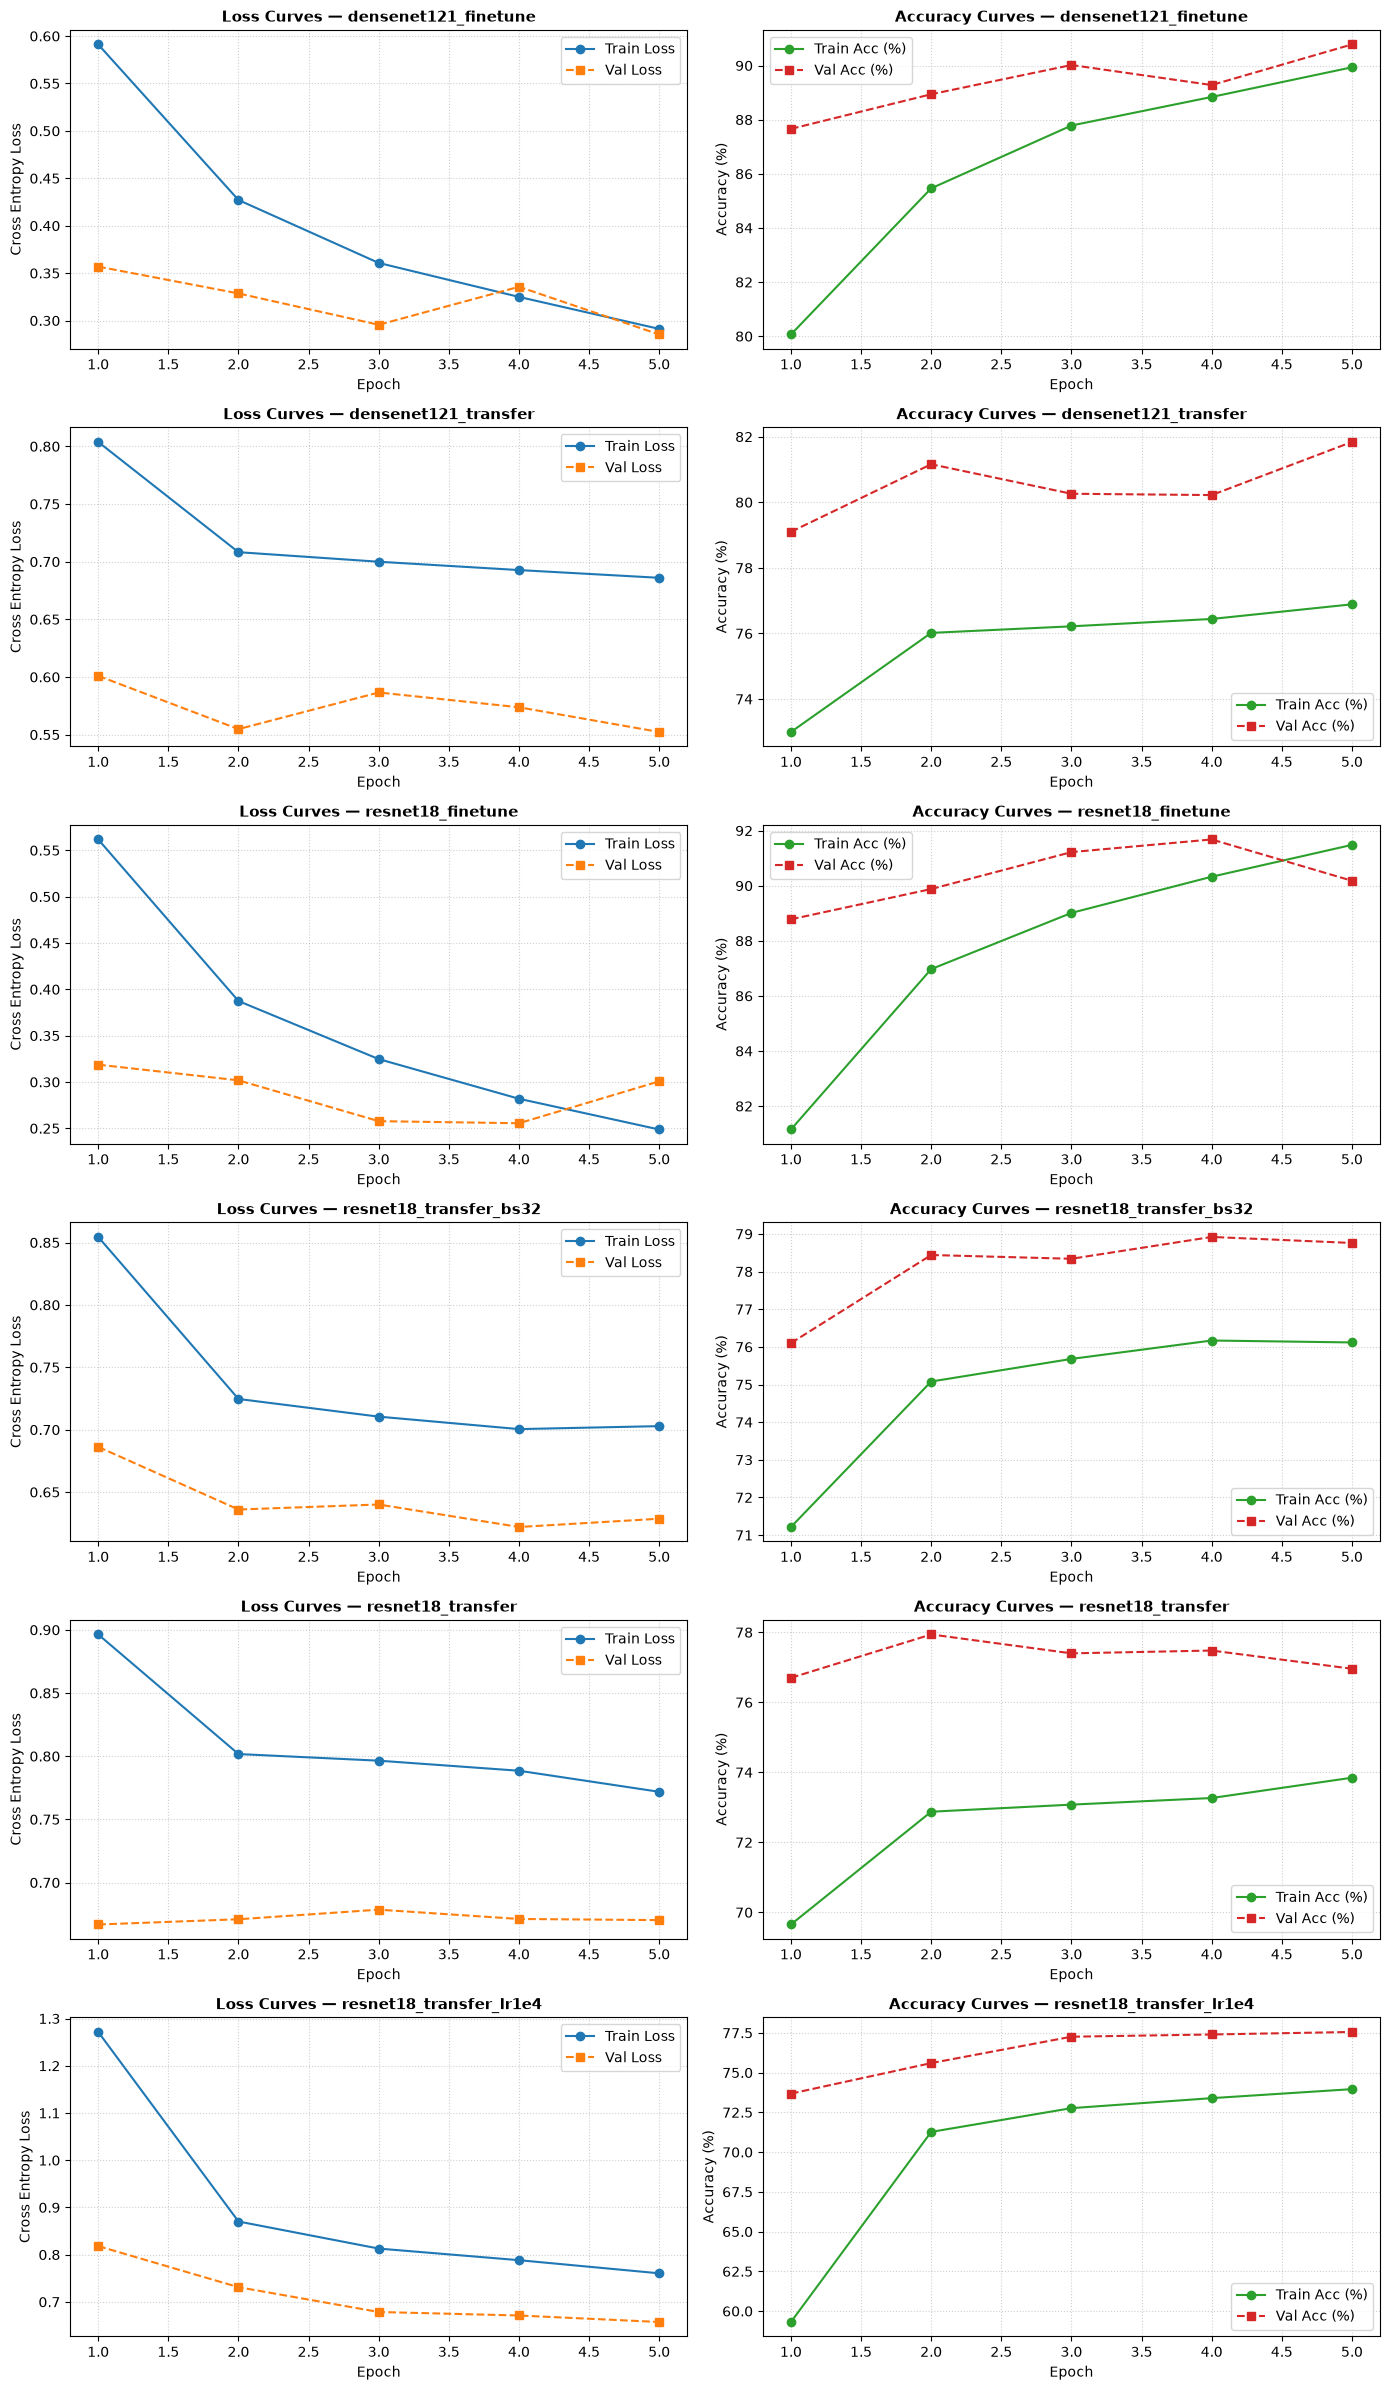

In [4]:
if histories:
    num_exps = len(histories)
    fig, axes = plt.subplots(num_exps, 2, figsize=(14, 4 * num_exps), squeeze=False)
    
    for idx, (exp_name, h_data) in enumerate(histories.items()):
        h = h_data.get("history", {})
        epochs_range = range(1, len(h.get("train_loss", [])) + 1)
        
        # Subplot 1: Loss curves
        ax_loss = axes[idx, 0]
        ax_loss.plot(epochs_range, h.get("train_loss", []), marker="o", label="Train Loss", color="#1f77b4")
        ax_loss.plot(epochs_range, h.get("val_loss", []), marker="s", label="Val Loss", color="#ff7f0e", linestyle="--")
        ax_loss.set_title(f"Loss Curves — {exp_name}", fontsize=11, fontweight="bold")
        ax_loss.set_xlabel("Epoch")
        ax_loss.set_ylabel("Cross Entropy Loss")
        ax_loss.grid(True, linestyle=":", alpha=0.6)
        ax_loss.legend()
        
        # Subplot 2: Accuracy curves
        ax_acc = axes[idx, 1]
        ax_acc.plot(epochs_range, h.get("train_acc", []), marker="o", label="Train Acc (%)", color="#2ca02c")
        ax_acc.plot(epochs_range, h.get("val_acc", []), marker="s", label="Val Acc (%)", color="#d62728", linestyle="--")
        ax_acc.set_title(f"Accuracy Curves — {exp_name}", fontsize=11, fontweight="bold")
        ax_acc.set_xlabel("Epoch")
        ax_acc.set_ylabel("Accuracy (%)")
        ax_acc.grid(True, linestyle=":", alpha=0.6)
        ax_acc.legend()
        
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có file history JSON nào trong outputs/metrics/. Biểu đồ sẽ hiển thị sau khi thực thi Phase 5.")

## 4. So sánh Test Accuracy, Thời gian Huấn luyện và Tham số Trainable
So sánh định lượng giữa các phương pháp:
- **Test Accuracy (%):** Khả năng tổng quát hóa trên 10.000 ảnh kiểm thử độc lập của CIFAR-10.
- **Thời gian huấn luyện:** Tổng thời gian thực thi (giây) trên phần cứng CPU Intel Core i5.
- **Số lượng tham số Trainable:** Khối lượng tham số cần tính gradient và cập nhật trọng số qua optimizer.

=== DỮ LIỆU ĐỐI CHIẾU ĐỊNH LƯỢNG ===


,Experiment,Test Accuracy (%),Total Time (s),Trainable Params
0,densenet121_finetune,90.65,642.160168,2170378
1,densenet121_transfer,81.34,543.467472,10250
2,resnet18_finetune,90.24,435.419009,8398858
3,resnet18_transfer_bs32,79.04,321.416950,5130
4,resnet18_transfer_lr1e4,78.32,363.696878,5130
5,resnet18_transfer,77.98,335.164289,5130


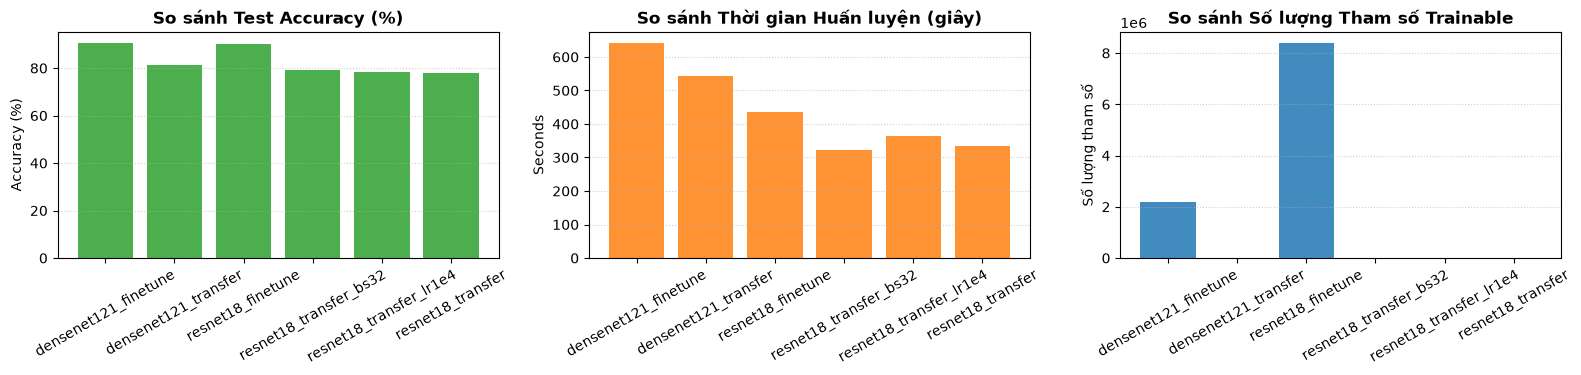

In [5]:
if test_metrics:
    comp_data = []
    for exp_name, tm in test_metrics.items():
        hist = histories.get(exp_name, {})
        cfg = hist.get("config", {})
        t_acc = tm.get("test_accuracy", 0.0)
        tot_time = hist.get("total_time_seconds", 0.0)
        
        # Đếm số lượng tham số trainable
        from lab2.models import build_model, count_parameters
        m_name = cfg.get("model_name", "resnet18")
        method = cfg.get("method", "transfer")
        try:
            m = build_model(m_name, method=method, num_classes=10, pretrained=False)
            trainable_p = count_parameters(m)["trainable"]
        except Exception:
            trainable_p = 0
            
        comp_data.append({
            "Experiment": exp_name,
            "Test Accuracy (%)": t_acc,
            "Total Time (s)": tot_time,
            "Trainable Params": trainable_p
        })
        
    df_comp = pd.DataFrame(comp_data)
    print("=== DỮ LIỆU ĐỐI CHIẾU ĐỊNH LƯỢNG ===")
    display(df_comp)
    
    # Vẽ biểu đồ so sánh cột
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    
    # 1. Test Accuracy
    axes[0].bar(df_comp["Experiment"], df_comp["Test Accuracy (%)"], color="#2ca02c", alpha=0.85)
    axes[0].set_title("So sánh Test Accuracy (%)", fontweight="bold")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].tick_params(axis="x", rotation=30)
    axes[0].grid(axis="y", linestyle=":", alpha=0.6)
    
    # 2. Total Time
    axes[1].bar(df_comp["Experiment"], df_comp["Total Time (s)"], color="#ff7f0e", alpha=0.85)
    axes[1].set_title("So sánh Thời gian Huấn luyện (giây)", fontweight="bold")
    axes[1].set_ylabel("Seconds")
    axes[1].tick_params(axis="x", rotation=30)
    axes[1].grid(axis="y", linestyle=":", alpha=0.6)
    
    # 3. Trainable Parameters
    axes[2].bar(df_comp["Experiment"], df_comp["Trainable Params"], color="#1f77b4", alpha=0.85)
    axes[2].set_title("So sánh Số lượng Tham số Trainable", fontweight="bold")
    axes[2].set_ylabel("Số lượng tham số")
    axes[2].tick_params(axis="x", rotation=30)
    axes[2].grid(axis="y", linestyle=":", alpha=0.6)
    
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có dữ liệu test metrics để vẽ biểu đồ so sánh.")

## 5. Độ chính xác theo từng lớp và Phân tích Cặp lớp nhầm nhiều nhất
Khảo sát năng lực phân loại trên từng lớp trong 10 lớp của CIFAR-10 (`airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, `truck`):
- Xác định những lớp có độ chính xác cao nhất (dễ nhận dạng) và thấp nhất (khó phân biệt).
- Tự động trích xuất các cặp lớp có số lượng mẫu bị dự đoán nhầm nhiều nhất từ ma trận nhầm lẫn (`confusion_matrix`) thông qua thuật toán lọc bỏ đường chéo chính.

In [6]:
from lab2.data import CIFAR10_CLASSES

if test_metrics:
    per_class_rows = []
    for exp_name, tm in test_metrics.items():
        pc = tm.get("per_class_accuracy", {})
        row = {"Experiment": exp_name}
        row.update(pc)
        per_class_rows.append(row)
        
    df_per_class = pd.DataFrame(per_class_rows)
    print("=== ĐỘ CHÍNH XÁC THEO TỪNG LỚP (PER-CLASS ACCURACY %) ===")
    display(df_per_class)
    
    print("\n=== TOP 3 CẶP LỚP NHẦM LẪN NHIỀU NHẤT THEO TỪNG MÔ HÌNH ===")
    for exp_name, tm in test_metrics.items():
        cm = np.array(tm.get("confusion_matrix", []))
        if cm.size == 0 or cm.shape != (10, 10):
            continue
            
        # Tìm các cặp (i, j) với i != j có giá trị nhầm lẫn cao nhất
        confused_pairs = []
        for i in range(10):
            for j in range(10):
                if i != j and cm[i, j] > 0:
                    confused_pairs.append((CIFAR10_CLASSES[i], CIFAR10_CLASSES[j], cm[i, j]))
                    
        confused_pairs.sort(key=lambda x: x[2], reverse=True)
        top3 = confused_pairs[:3]
        print(f"\n[{exp_name}]:")
        for rank, (true_cls, pred_cls, count) in enumerate(top3, 1):
            print(f"  {rank}. Lớp thực tế '{true_cls}' nhầm thành '{pred_cls}': {count} mẫu")
else:
    print("Chưa có file test metrics để phân tích ma trận nhầm lẫn chi tiết.")

=== ĐỘ CHÍNH XÁC THEO TỪNG LỚP (PER-CLASS ACCURACY %) ===


,Experiment,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
0,densenet121_finetune,94.0,93.0,87.0,81.6,86.6,84.3,94.4,96.2,93.9,95.5
1,densenet121_transfer,87.6,85.7,74.2,71.4,76.1,70.9,86.3,83.4,85.9,91.9
2,resnet18_finetune,95.0,80.4,90.4,77.8,90.4,91.6,91.4,92.7,94.3,98.4
3,resnet18_transfer_bs32,78.3,83.0,65.4,72.2,80.2,69.7,82.8,79.6,88.3,90.9
4,resnet18_transfer_lr1e4,81.4,88.0,62.4,64.2,67.3,72.5,89.7,82.1,85.9,89.7
5,resnet18_transfer,82.0,85.6,61.8,70.1,70.8,61.9,91.9,80.9,87.3,87.5



=== TOP 3 CẶP LỚP NHẦM LẪN NHIỀU NHẤT THEO TỪNG MÔ HÌNH ===

[densenet121_finetune]:
  1. Lớp thực tế 'dog' nhầm thành 'cat': 92 mẫu
  2. Lớp thực tế 'cat' nhầm thành 'dog': 90 mẫu
  3. Lớp thực tế 'deer' nhầm thành 'horse': 47 mẫu

[densenet121_transfer]:
  1. Lớp thực tế 'dog' nhầm thành 'cat': 141 mẫu
  2. Lớp thực tế 'automobile' nhầm thành 'truck': 109 mẫu
  3. Lớp thực tế 'ship' nhầm thành 'airplane': 75 mẫu

[resnet18_finetune]:
  1. Lớp thực tế 'automobile' nhầm thành 'truck': 174 mẫu
  2. Lớp thực tế 'cat' nhầm thành 'dog': 138 mẫu
  3. Lớp thực tế 'dog' nhầm thành 'cat': 59 mẫu

[resnet18_transfer_bs32]:
  1. Lớp thực tế 'dog' nhầm thành 'cat': 163 mẫu
  2. Lớp thực tế 'bird' nhầm thành 'deer': 106 mẫu
  3. Lớp thực tế 'automobile' nhầm thành 'truck': 105 mẫu

[resnet18_transfer_lr1e4]:
  1. Lớp thực tế 'dog' nhầm thành 'cat': 113 mẫu
  2. Lớp thực tế 'deer' nhầm thành 'horse': 102 mẫu
  3. Lớp thực tế 'bird' nhầm thành 'frog': 101 mẫu

[resnet18_transfer]:
  1. Lớp thực tế 

## 6. Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix Figures)
Hiển thị các biểu đồ Confusion Matrix định dạng PNG đã được tạo tự động trong thư mục `outputs/figures/`.


=== MA TRẬN NHẦM LẪN: densenet121_finetune ===


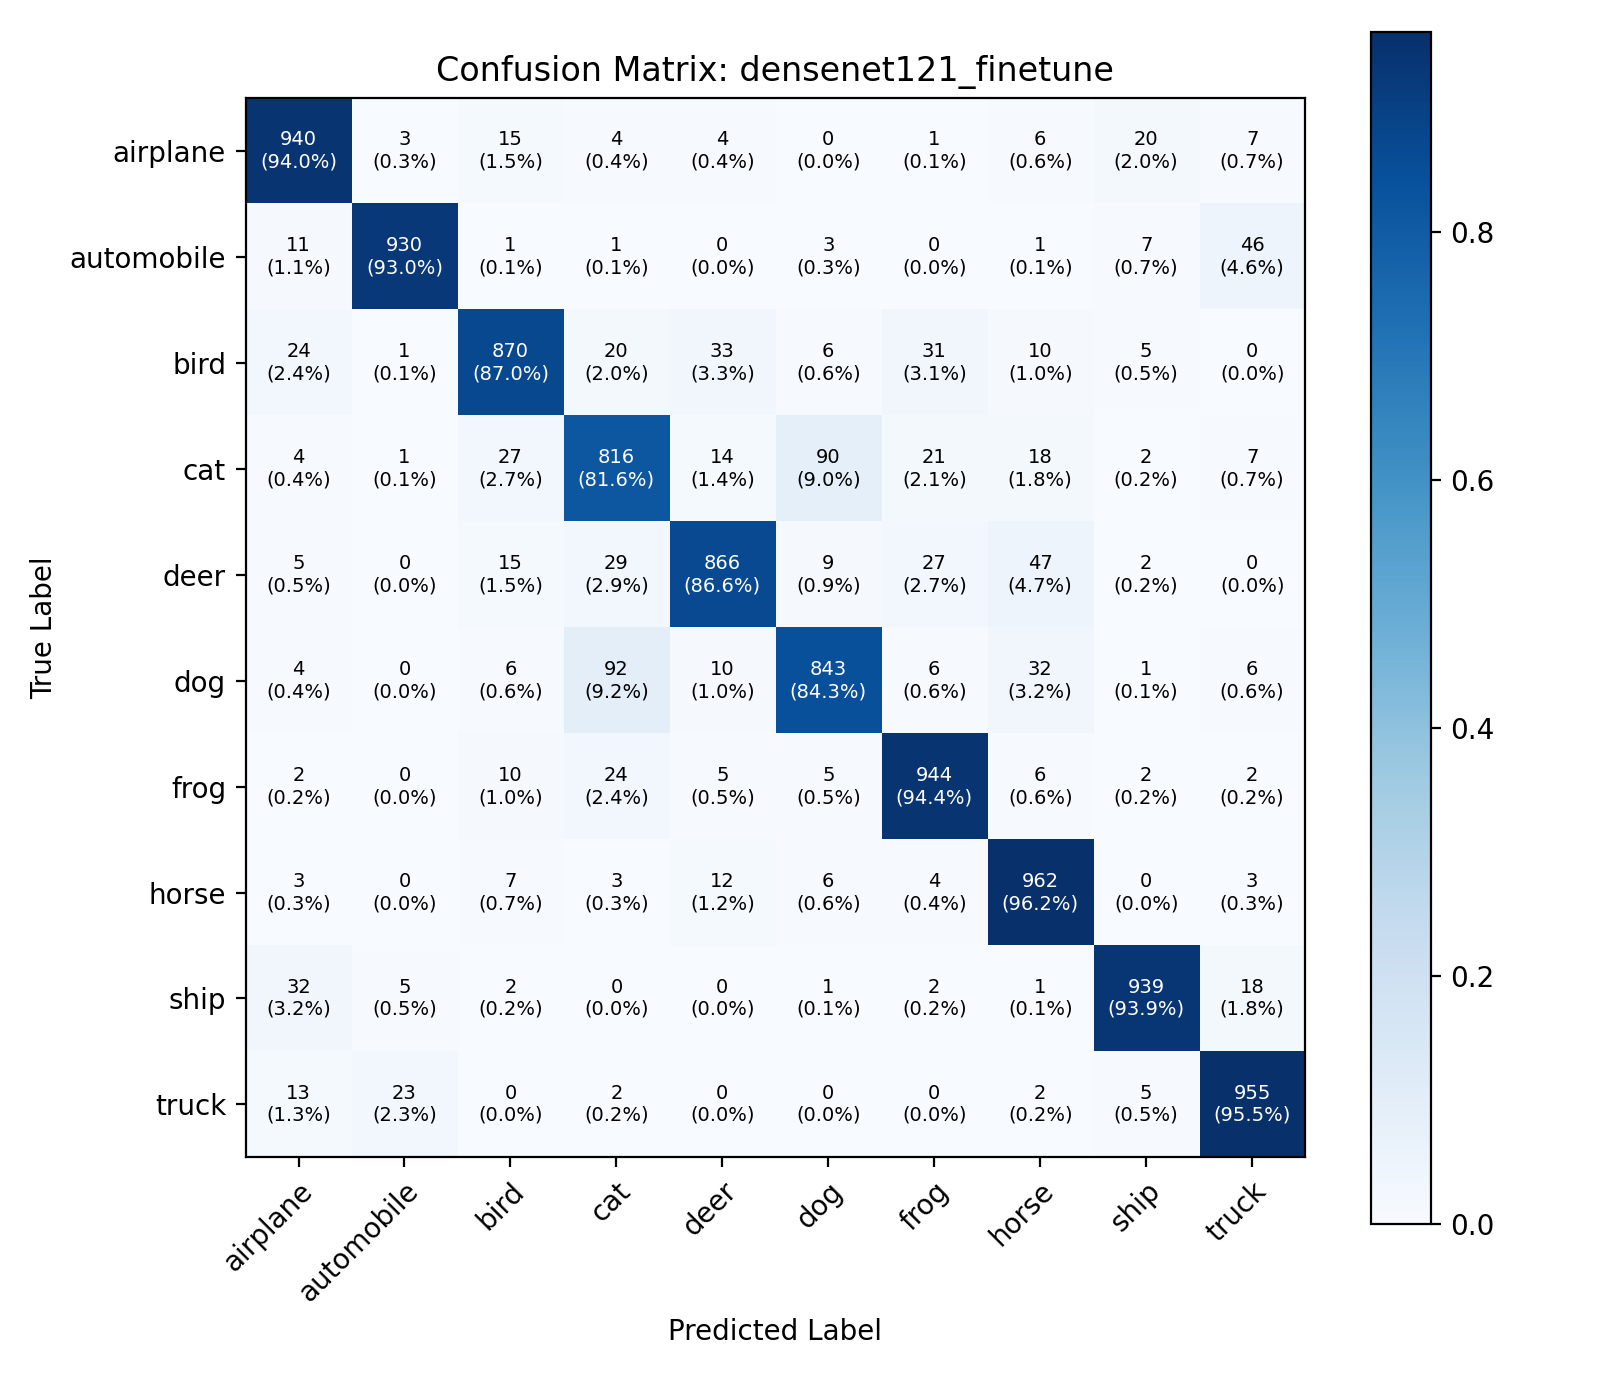


=== MA TRẬN NHẦM LẪN: densenet121_transfer ===


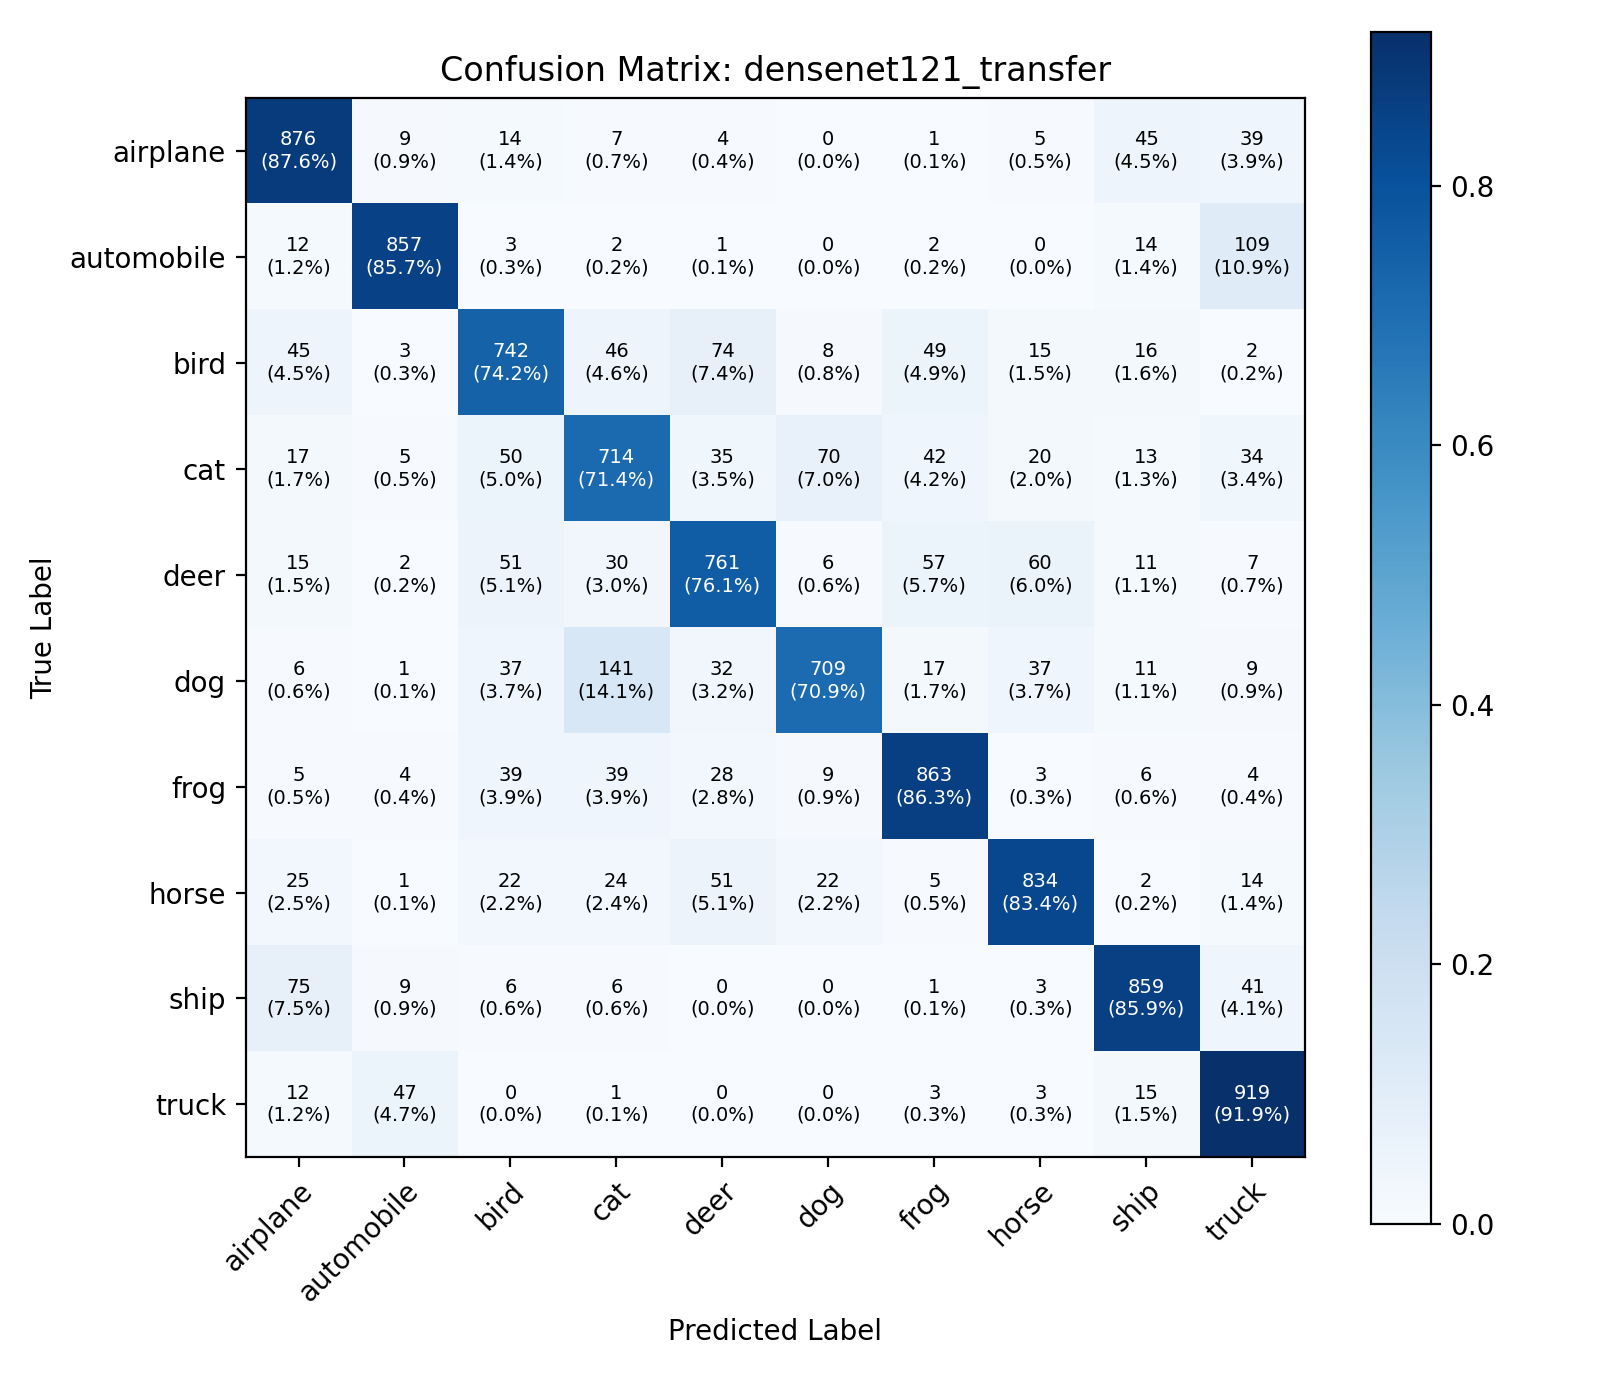


=== MA TRẬN NHẦM LẪN: resnet18_finetune ===


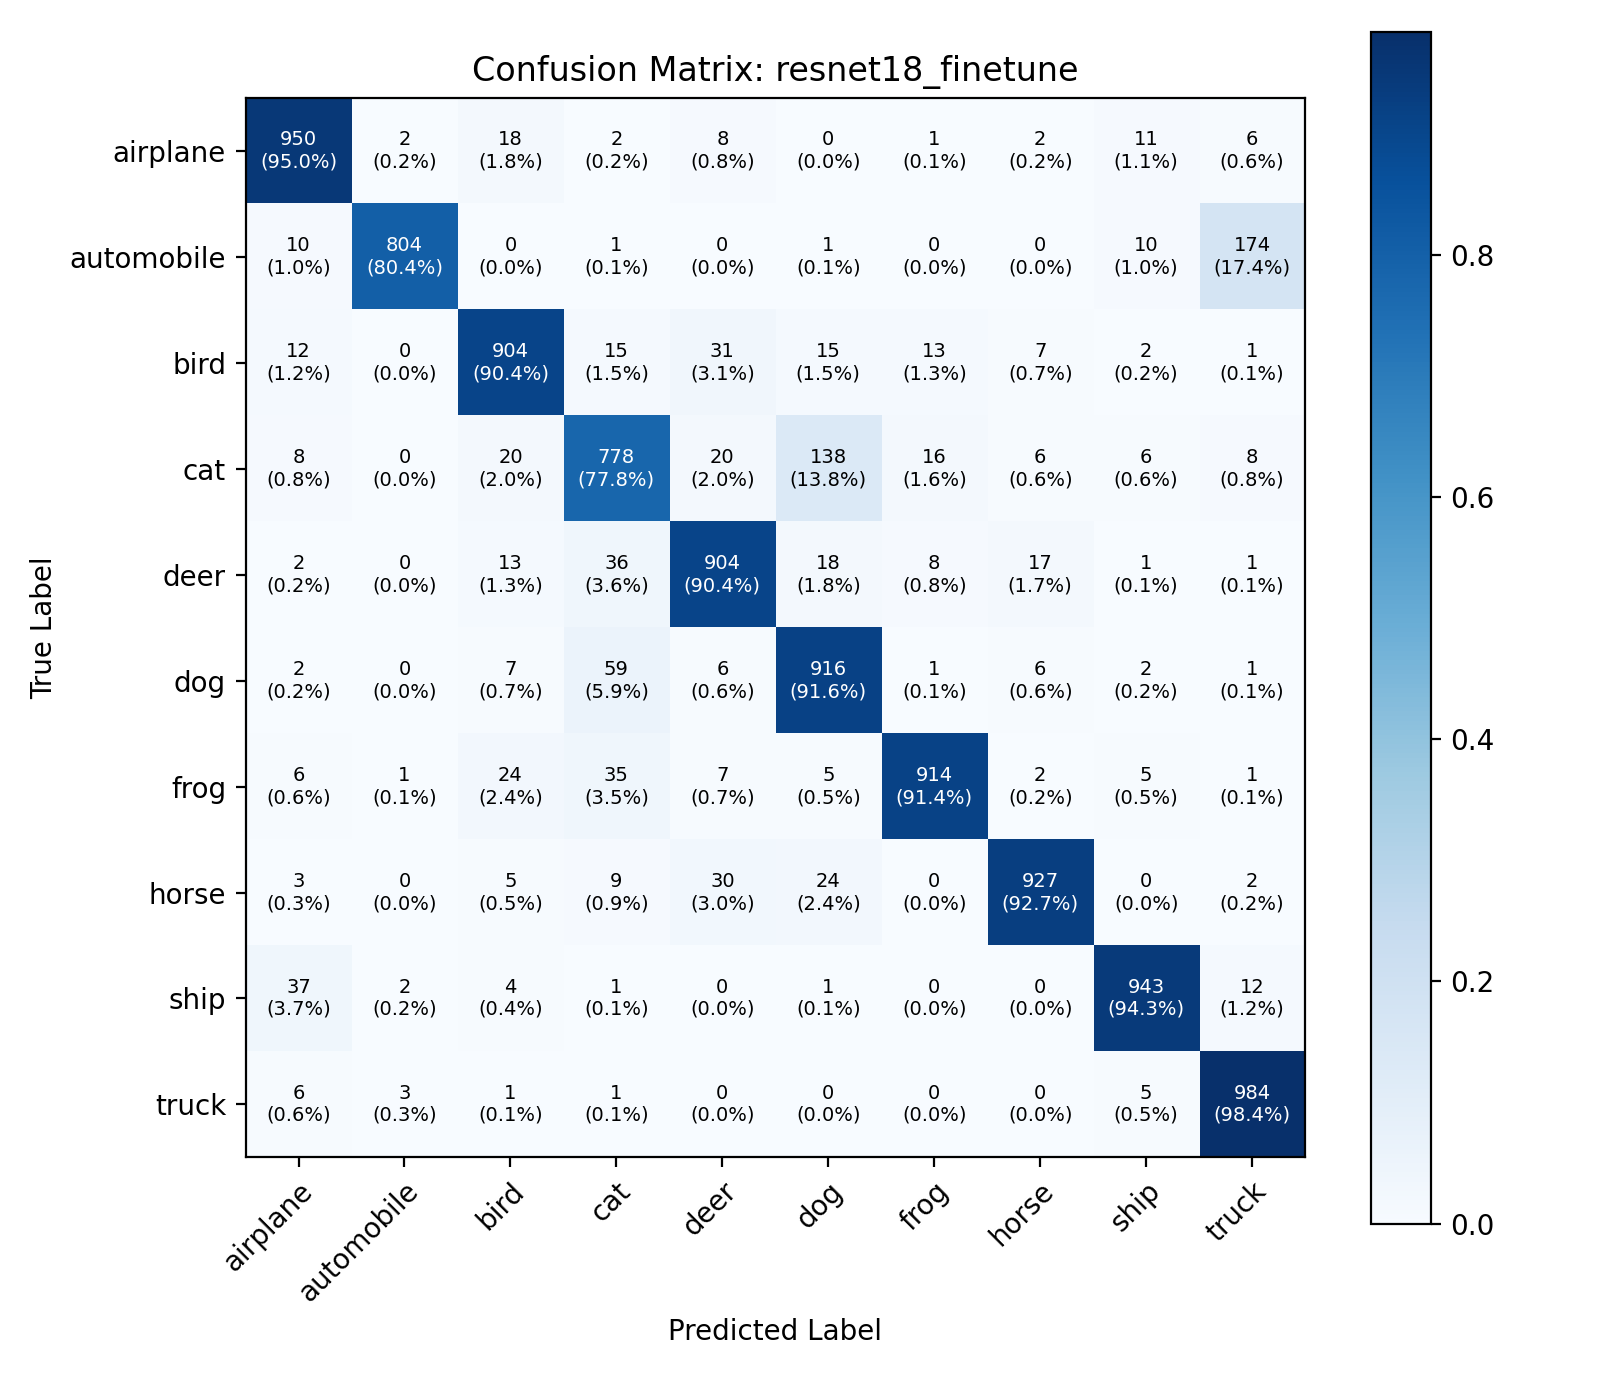


=== MA TRẬN NHẦM LẪN: resnet18_transfer_bs32 ===


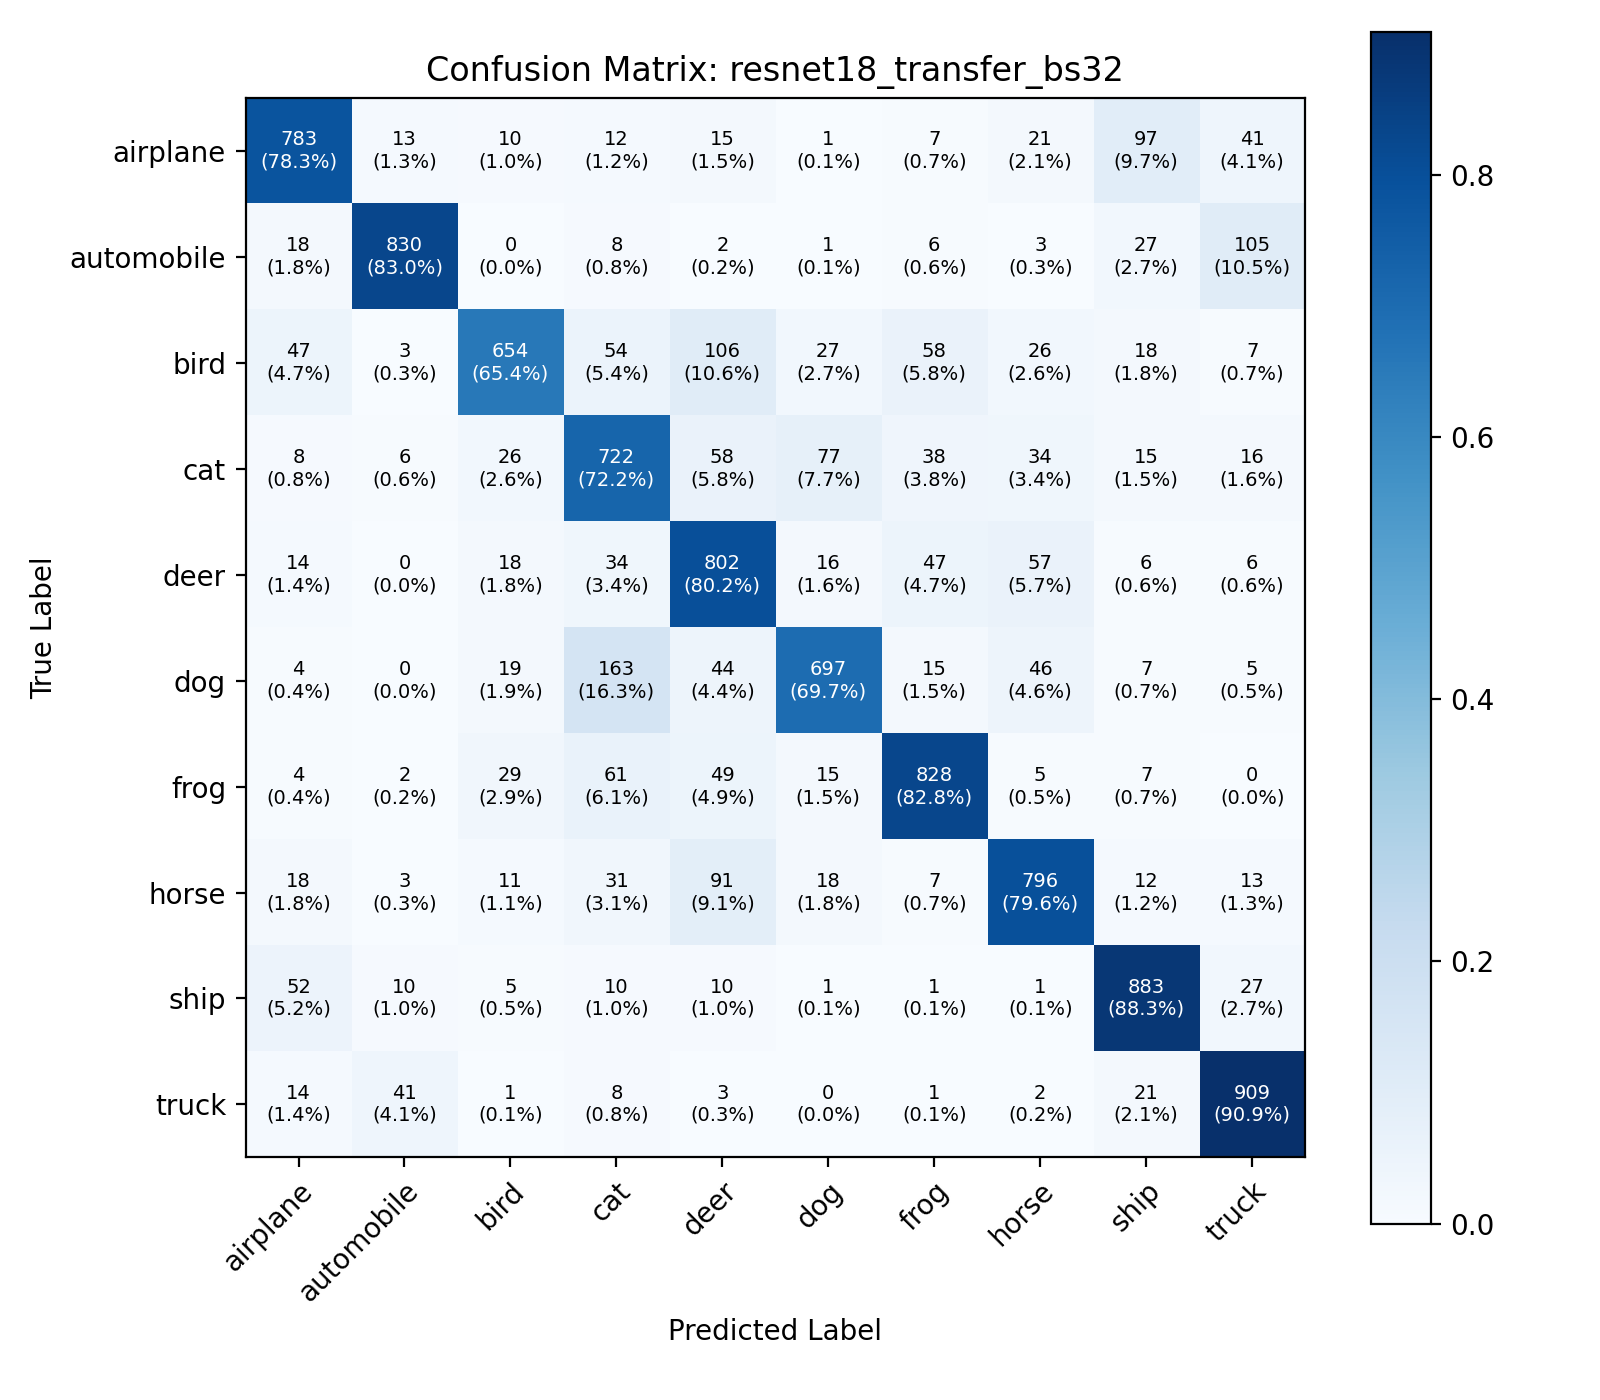


=== MA TRẬN NHẦM LẪN: resnet18_transfer ===


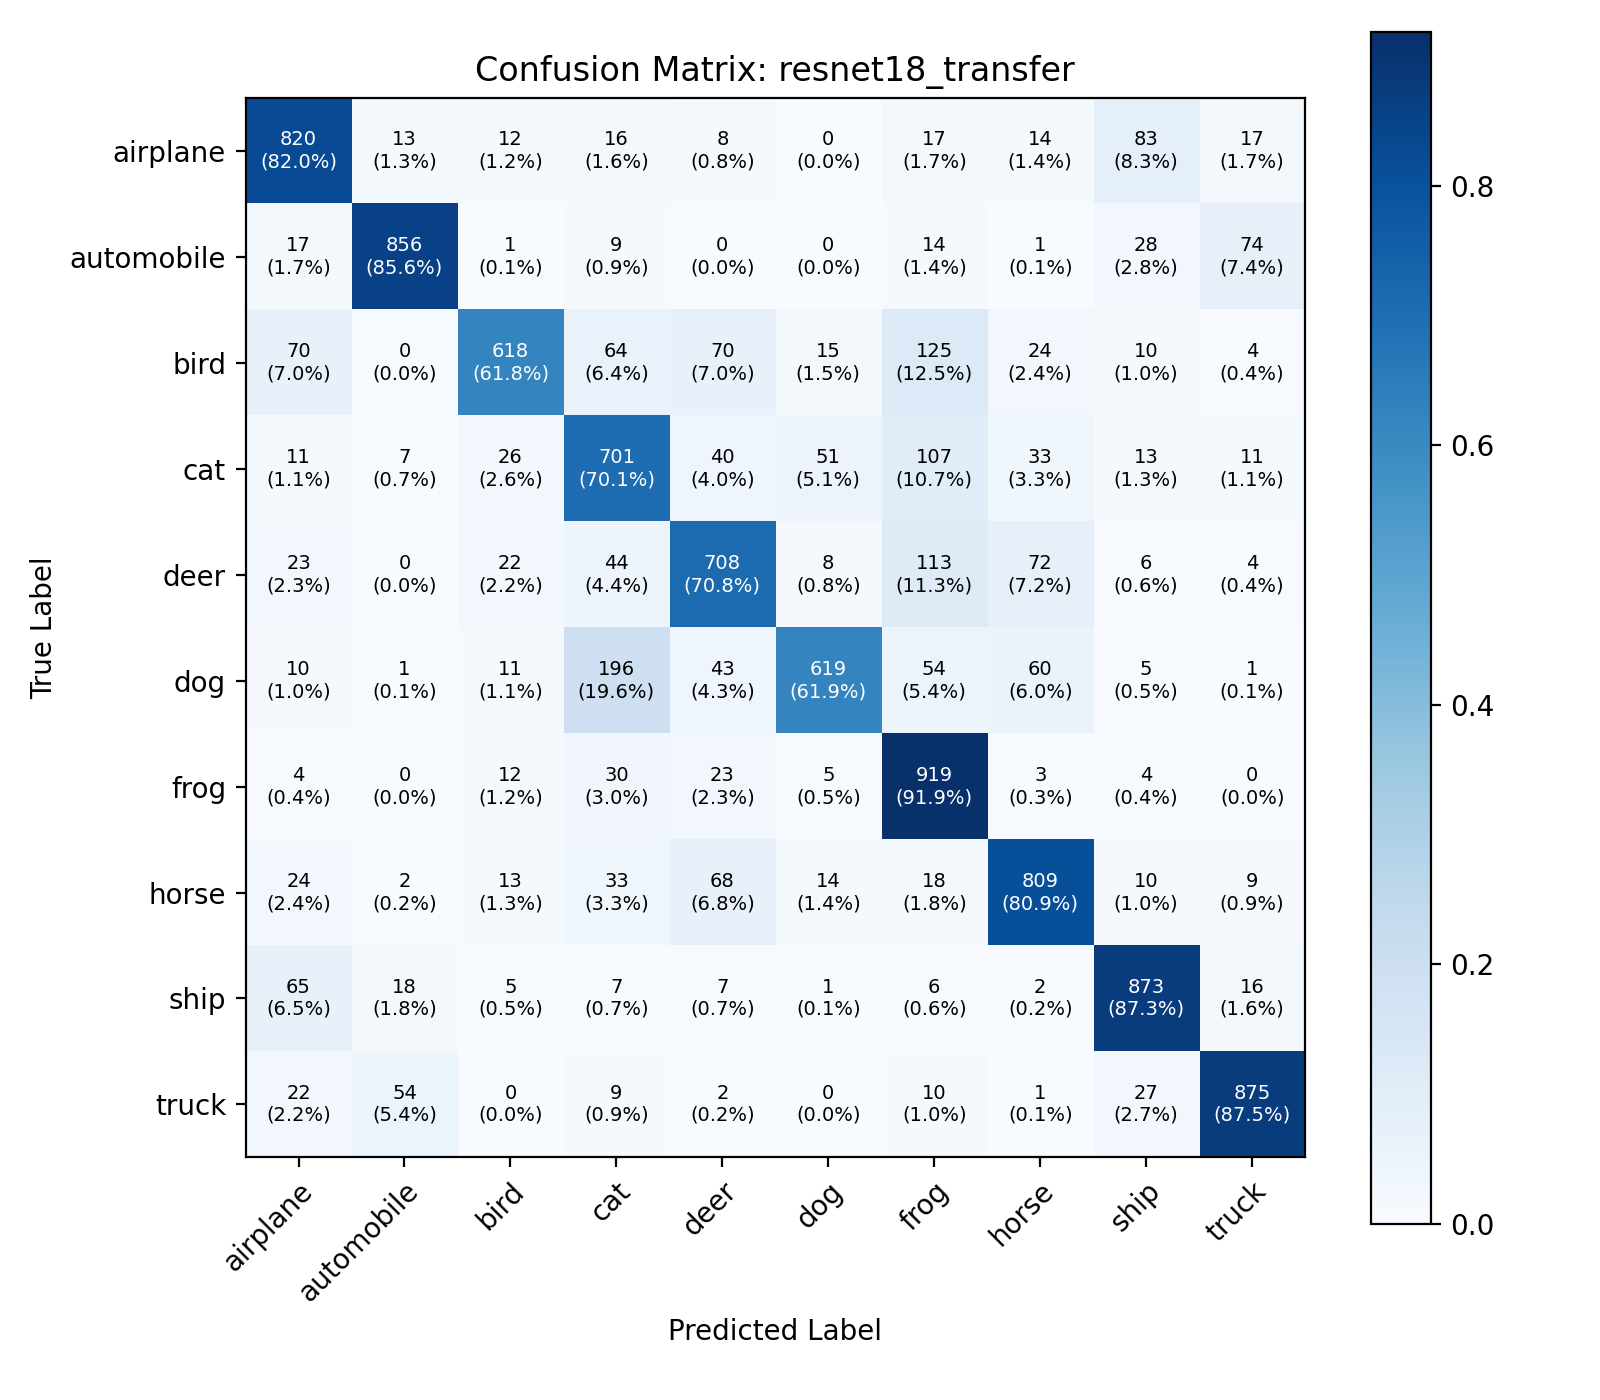


=== MA TRẬN NHẦM LẪN: resnet18_transfer_lr1e4 ===


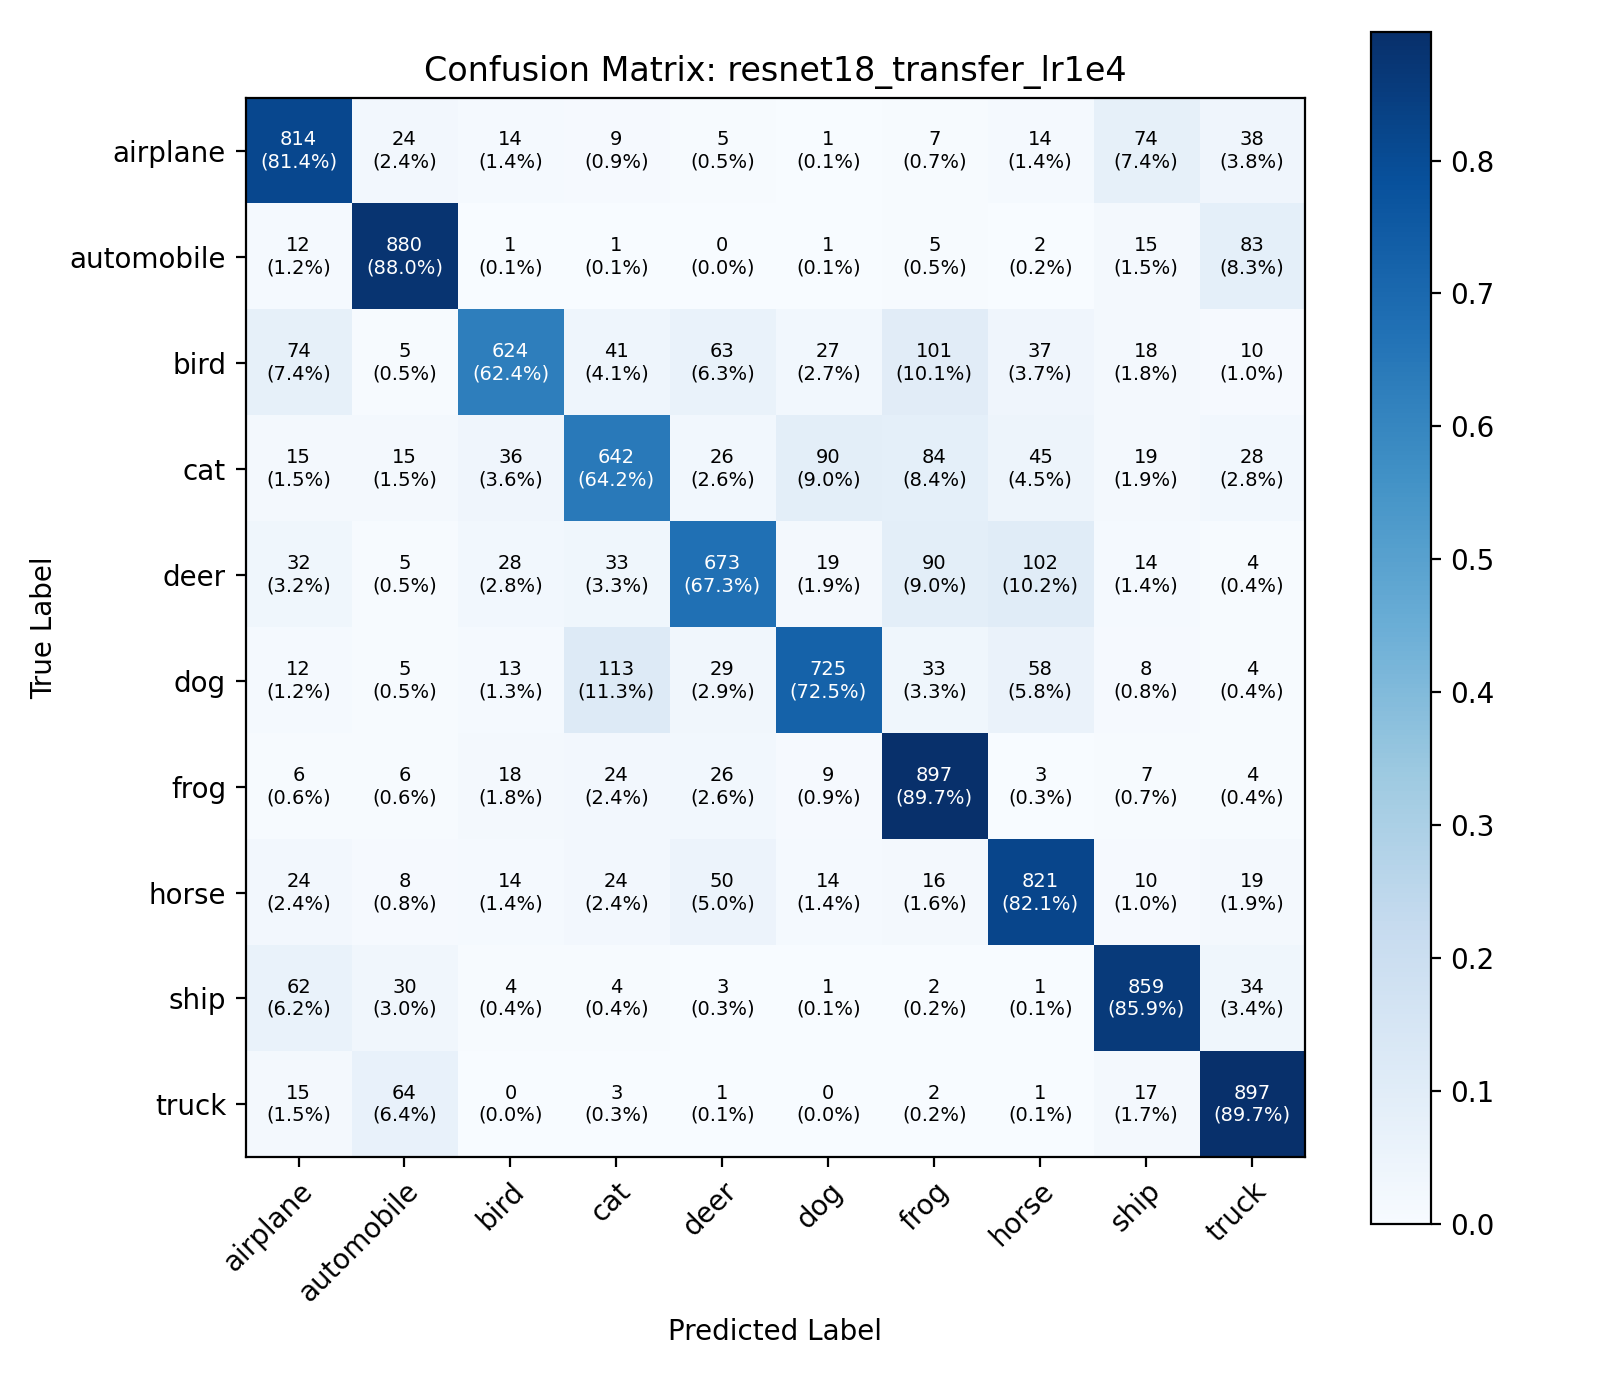

In [7]:
from IPython.display import Image, display

cm_figures = sorted(glob.glob("./outputs/figures/*_confusion_matrix.png"))
if cm_figures:
    for fig_path in cm_figures:
        exp_id = os.path.basename(fig_path).replace("_confusion_matrix.png", "")
        print(f"\n=== MA TRẬN NHẦM LẪN: {exp_id} ===")
        display(Image(filename=fig_path))
else:
    print("Chưa tìm thấy biểu đồ ma trận nhầm lẫn PNG trong outputs/figures/.")
    print("Các hình ảnh sẽ tự động được tạo khi chạy xong kiểm thử ở Phase 5.")

## 7. Phân tích hiện tượng Quá khớp (Overfitting) và Dưới khớp (Underfitting)
### Tiêu chí khoa học đánh giá:
1. **Dưới khớp (Underfitting):** Cả Train Accuracy và Validation Accuracy đều ở mức thấp, Train Loss chưa bão hòa, mô hình chưa học đủ biểu diễn đặc trưng phân biệt.
2. **Quá khớp (Overfitting):** Train Accuracy tiếp tục tăng cao trong khi Validation Accuracy bão hòa hoặc suy giảm; Train Loss giảm sâu nhưng Validation Loss bắt đầu tăng ngược trở lại (phân kỳ giữa Train và Val).

### Ghi nhận thực tế từ dữ liệu huấn luyện:
Dựa trên đồ thị Loss và Accuracy ở Mục 3:
- Nếu Validation Loss bắt đầu phân kỳ và tăng trong khi Train Loss tiếp tục giảm, mô hình có biểu hiện overfitting; khi đó cần bổ sung kỹ thuật điều chuẩn (weight decay, dropout, hoặc data augmentation mạnh hơn).
- Nếu cả Train Loss và Validation Loss đều đang trên đà giảm ổn định sau 5 epochs, mô hình đang hội tụ tốt và có thể đạt độ chính xác cao hơn khi kéo dài số epoch huấn luyện.

> **Lưu ý nguyên tắc nghiên cứu:** Toàn bộ kết quả thực nghiệm trong bài báo cáo này được thực hiện trên một hạt giống ngẫu nhiên duy nhất (`seed=42`). Do đó, các kết luận chỉ mang tính ghi nhận thực nghiệm trong phạm vi cấu hình kiểm thử, không thể ngoại suy tuyệt đối cho mọi điều kiện nếu chưa kiểm định thống kê qua nhiều lượt chạy độc lập.

## 8. Tổng kết và Kiến nghị
### Kết luận rút ra từ thực nghiệm:
1. **Kiến trúc mạng:** So sánh giữa ResNet18 và DenseNet121 về độ chính xác và hiệu suất tham số.
2. **Phương pháp thích nghi:** Hiệu quả của Fine-Tuning so với Transfer Learning thuần túy.
3. **Siêu tham số:** Tác động của Learning Rate ($10^{-3}$ vs. $10^{-4}$) và Batch Size ($16$ vs. $32$) đối với tốc độ học và độ ổn định trên CPU.

---
*Báo cáo tổng hợp số liệu thực nghiệm từ các tệp cấu hình và metric trong repository `DL_Lab2_Nhom1`.*